In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [10]:

%pip install xlrd


Note: you may need to restart the kernel to use updated packages.


In [11]:

import pandas as pd

df = pd.read_excel(
    "Dataset/sample_-_superstore.xls",
    sheet_name="Orders"
)

df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [12]:

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])


Total rows: 10194
Total columns: 21


In [13]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names and data types
df.info()


Dataset shape: (10194, 21)
<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  str           
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  str           
 8   Country/Region  10194 non-null  str           
 9   City            10194 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  str           
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  str   

In [14]:

# Count missing values in each column
df.isnull().sum()


Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [15]:

# Count completely identical rows
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [16]:

# Calculate key sales metrics

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
profit_margin = (total_profit / total_sales) * 100
total_orders = df["Order ID"].nunique()

print(f"Total Revenue: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Total Orders: {total_orders:,}")


Total Revenue: $2,326,534.35
Total Profit: $292,296.81
Profit Margin: 12.56%
Total Orders: 5,111


In [18]:


regional_sales = (
    df.groupby("Region")[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
)

regional_sales


,Sales,Profit
Region,,
West,739813.6085,110798.8170
East,691828.1680,94883.2603
Central,503170.6728,39865.3070
South,391721.9050,46749.4303


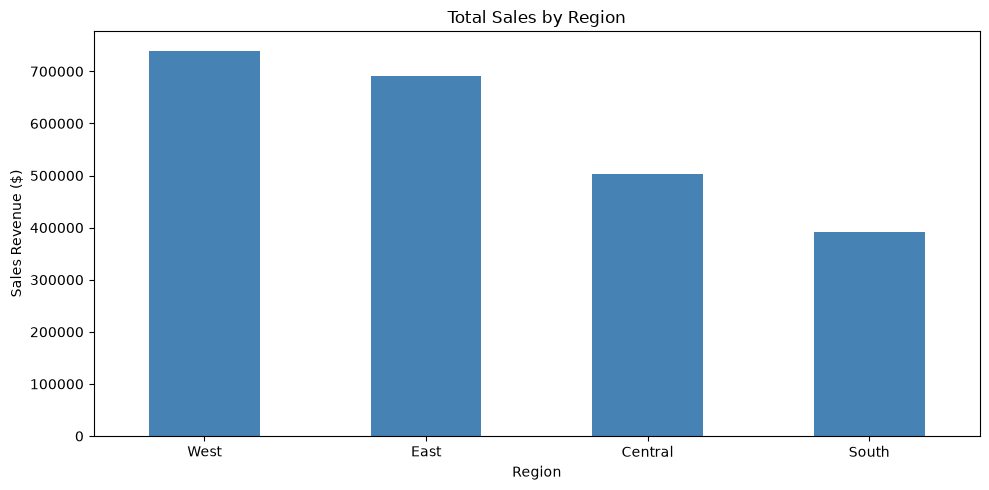

In [19]:

import matplotlib.pyplot as plt

regional_sales["Sales"].plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales Revenue ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [20]:

# Convert Order Date to datetime
df["Order Date"] = pd.to_datetime(df["Order Date"])

# Calculate monthly sales
monthly_sales = (
    df.set_index("Order Date")
    .resample("MS")["Sales"]
    .sum()
)

monthly_sales.head()


Order Date
2023-01-01    14518.055
2023-02-01     4519.892
2023-03-01    56933.909
2023-04-01    28295.345
2023-05-01    26319.767
Freq: MS, Name: Sales, dtype: float64

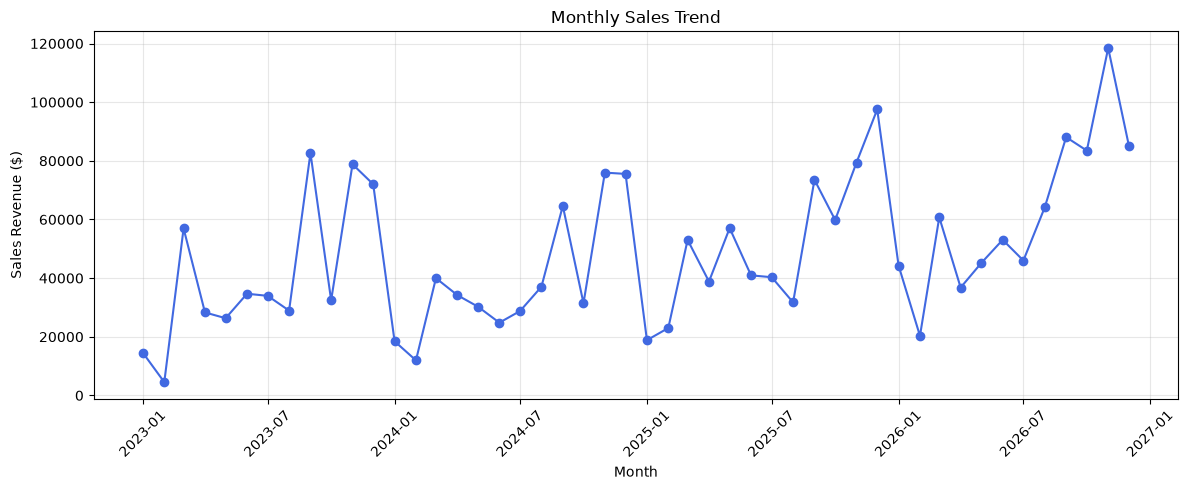

In [21]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    color="royalblue"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales Revenue ($)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [22]:

category_performance = (
    df.groupby("Category")[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
)

category_performance.round(2)


,Sales,Profit
Category,,
Technology,839893.28,146543.38
Furniture,754747.76,19730.00
Office Supplies,731893.31,126023.44


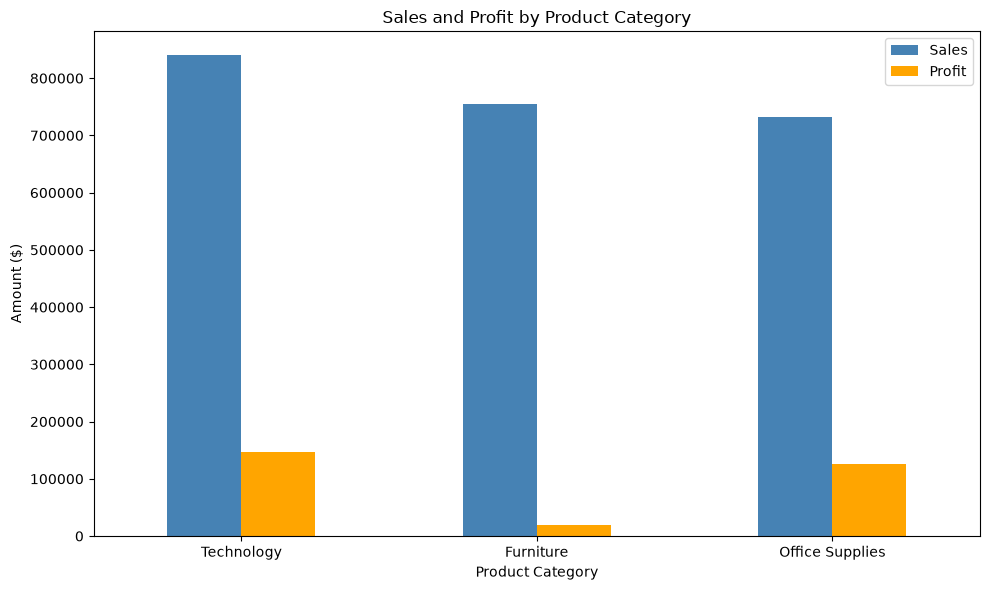

In [23]:

import matplotlib.pyplot as plt

category_performance.plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "orange"]
)

plt.title("Sales and Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.legend(["Sales", "Profit"])
plt.tight_layout()
plt.show()


In [24]:

most_profitable = category_performance["Profit"].idxmax()

print("Most profitable category:", most_profitable)


Most profitable category: Technology


In [25]:

top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products


Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

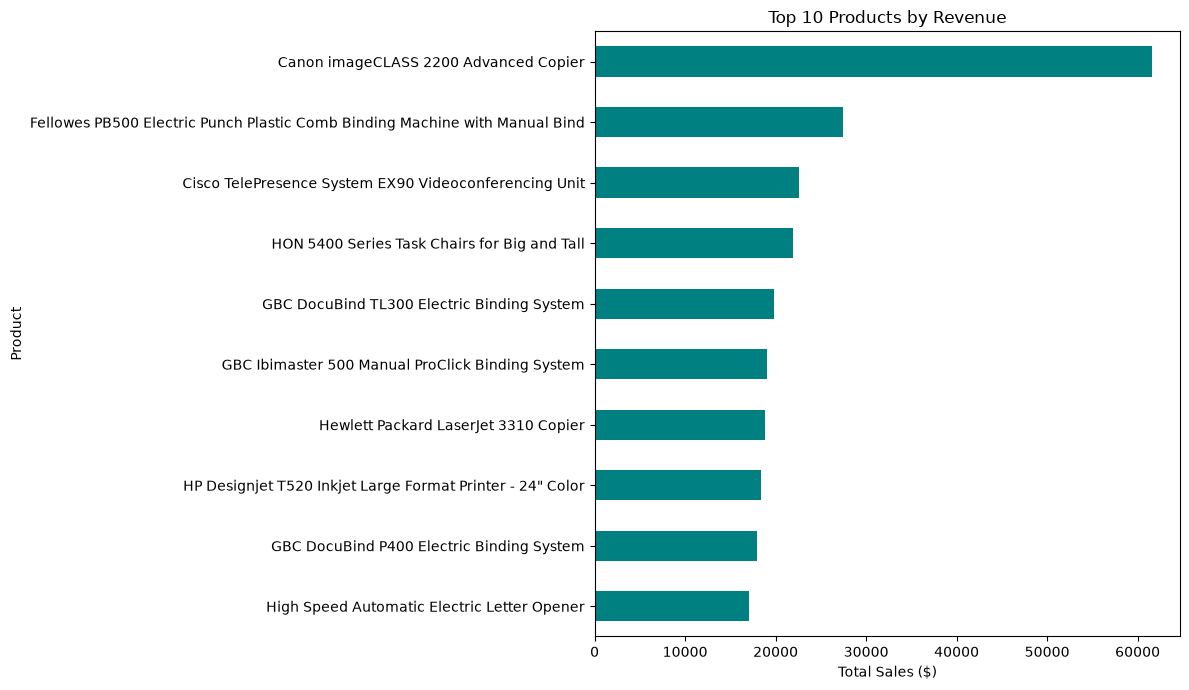

In [26]:

plt.figure(figsize=(12, 7))

top_products.sort_values().plot(
    kind="barh",
    color="teal"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Sales ($)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


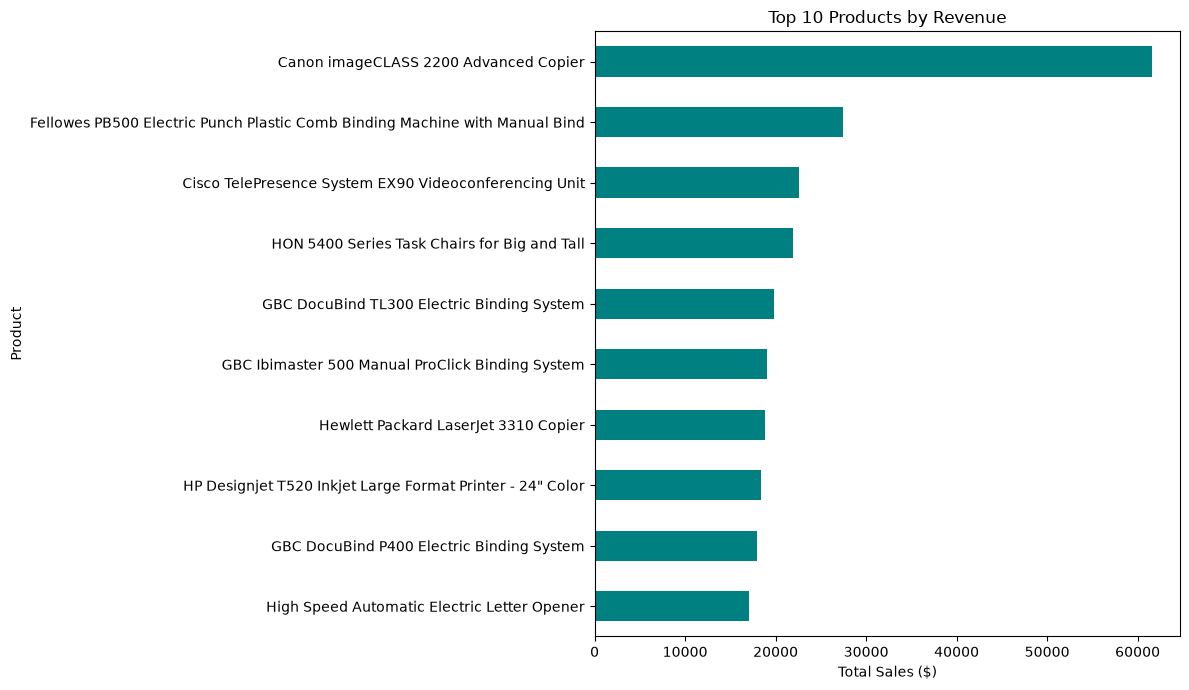

In [27]:

fig = plt.figure(figsize=(12, 7))

top_products.sort_values().plot(
    kind="barh",
    color="teal"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Sales ($)")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig(
    "Dashboard/top_10_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [28]:

%pip install streamlit plotly


Note: you may need to restart the kernel to use updated packages.


In [29]:

from pathlib import Path

Path("Dashboard").mkdir(exist_ok=True)

app_path = Path("Dashboard/app.py")
app_path.touch(exist_ok=True)

print("Dashboard file created:", app_path)


Dashboard file created: Dashboard/app.py


In [30]:

%%writefile Dashboard/app.py
import streamlit as st
import pandas as pd
import plotly.express as px
from pathlib import Path

# Page settings
st.set_page_config(
    page_title="Sales Performance Dashboard",
    page_icon="📊",
    layout="wide"
)

st.title("📊 Sales Performance Dashboard")
st.caption("Interactive retail sales analytics")

# Load dataset
@st.cache_data
def load_data():
    file_path = (
        Path(__file__).resolve().parent.parent
        / "Dataset"
        / "sample_-_superstore.xls"
    )
    data = pd.read_excel(file_path, sheet_name="Orders")
    data["Order Date"] = pd.to_datetime(data["Order Date"])
    return data

df = load_data()

# Sidebar filters
st.sidebar.header("Dashboard Filters")

regions = st.sidebar.multiselect(
    "Select Region",
    options=sorted(df["Region"].unique()),
    default=sorted(df["Region"].unique())
)

categories = st.sidebar.multiselect(
    "Select Category",
    options=sorted(df["Category"].unique()),
    default=sorted(df["Category"].unique())
)

filtered_df = df[
    df["Region"].isin(regions)
    & df["Category"].isin(categories)
].copy()

if filtered_df.empty:
    st.warning("No data matches your filters.")
    st.stop()

# Calculate KPIs
total_sales = filtered_df["Sales"].sum()
total_profit = filtered_df["Profit"].sum()
total_orders = filtered_df["Order ID"].nunique()
profit_margin = total_profit / total_sales * 100

st.subheader("Key Performance Indicators")

col1, col2, col3, col4 = st.columns(4)

col1.metric("Total Revenue", f"${total_sales:,.2f}")
col2.metric("Total Profit", f"${total_profit:,.2f}")
col3.metric("Profit Margin", f"{profit_margin:.2f}%")
col4.metric("Total Orders", f"{total_orders:,}")

# Regional sales
st.subheader("Regional Sales Performance")

regional = (
    filtered_df.groupby("Region", as_index=False)["Sales"]
    .sum()
)

fig_region = px.bar(
    regional,
    x="Region",
    y="Sales",
    color="Region",
    title="Total Sales by Region"
)

st.plotly_chart(fig_region, use_container_width=True)

# Monthly sales
st.subheader("Monthly Sales Trend")

monthly = (
    filtered_df
    .set_index("Order Date")
    .resample("MS")["Sales"]
    .sum()
    .reset_index()
)

fig_monthly = px.line(
    monthly,
    x="Order Date",
    y="Sales",
    markers=True,
    title="Monthly Revenue"
)

st.plotly_chart(fig_monthly, use_container_width=True)

# Category performance
st.subheader("Product Category Performance")

category = (
    filtered_df.groupby("Category", as_index=False)
    [["Sales", "Profit"]]
    .sum()
)

fig_category = px.bar(
    category,
    x="Category",
    y=["Sales", "Profit"],
    barmode="group",
    title="Sales and Profit by Category"
)

st.plotly_chart(fig_category, use_container_width=True)

# Top products
st.subheader("Top 10 Products")

top_products = (
    filtered_df.groupby("Product Name", as_index=False)
    ["Sales"]
    .sum()
    .nlargest(10, "Sales")
    .sort_values("Sales")
)

fig_products = px.bar(
    top_products,
    x="Sales",
    y="Product Name",
    orientation="h",
    title="Top 10 Products by Revenue"
)

st.plotly_chart(fig_products, use_container_width=True)

st.caption("Sales Performance Analytics | Python & Streamlit")


Overwriting Dashboard/app.py


In [31]:

cd ~/Desktop/Sales-Performance-Analytics
streamlit run Dashboard/app.py


SyntaxError: invalid syntax (1350820970.py, line 1)

In [32]:

requirements = """streamlit
pandas
plotly
xlrd
"""

with open("requirements.txt", "w") as f:
    f.write(requirements)

print("requirements.txt created successfully!")


requirements.txt created successfully!


In [33]:

gitignore = """.ipynb_checkpoints/
__pycache__/
.venv/
.DS_Store
"""

with open(".gitignore", "w") as f:
    f.write(gitignore)

print(".gitignore created successfully!")


.gitignore created successfully!


In [34]:

from pathlib import Path

readme = """# Sales Performance Analytics Dashboard

An interactive retail sales analytics dashboard built
using Python, Pandas, Plotly, and Streamlit.

## Project Overview

This project analyzes Superstore retail sales data to
explore revenue, profitability, regional performance,
monthly sales trends, and product performance.

## Technologies

- Python
- Pandas
- Matplotlib
- Plotly
- Streamlit
- Jupyter Notebook

## Dashboard Features

- Total revenue, profit, profit margin, and order KPIs
- Interactive regional and product category filters
- Monthly revenue trends
- Regional sales performance
- Sales and profit comparison by category
- Top 10 products by revenue

## How to Run

Install dependencies:

    pip install -r requirements.txt

Launch the dashboard:

    streamlit run Dashboard/app.py

## Dataset

Sample Superstore retail sales dataset.

## Author

Takrim Chowdhury
MS in Business Analytics
University of Hartford
"""

Path("README.md").write_text(readme)

print("README.md created successfully!")


README.md created successfully!
